In [1]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import duckdb
import healpy as hp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import threading
import time

from astropy import constants as const
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
from astropy.io import fits
from astropy.visualization import make_lupton_rgb, ManualInterval
from astroquery.ipac.irsa import Irsa
from concurrent.futures import ThreadPoolExecutor, as_completed
from pprint import pprint
from pyvo.dal.exceptions import DALServiceError
from tqdm.auto import tqdm

from talltable import PixelQuery
from talltable.query import indices_to_hphigh_ranges, choose_filter_level
from talltable.pixel_query import _disc_rect_hphigh_ranges
from talltable.partition import find_partitions_disc

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


## configuration

In [2]:
Z_MIN, Z_MAX = 1.0, 1.01
N_GALAXIES = 1000          # sample size

WL_REST_HALPHA = 0.656    # µm
N_WL_BINS = 11
RESOLUTION = 120

QUERY_RADIUS_ARCMIN = 0.8

RNG = np.random.default_rng(110)

## load data

In [3]:
def load_catalog(path, subsample=None):
    with fits.open(path) as hdul:
        x = hdul[1].data

    print(f"  ..{len(x)} samples loaded")
    x = x[(x['Z'] > Z_MIN) & (x['Z'] < Z_MAX)]
    print(f"  ..{len(x)} samples after z cuts")

    if subsample and subsample < len(x):
        idx = RNG.choice(len(x), size=(subsample,))
        x = x[idx]
        print(f"  ..resampled to {len(x)} samples")
    
    return x

print("Loading data:")
data = load_catalog('../data/ELG_LOPnotqso_NGC_clustering.dat.fits', subsample=N_GALAXIES)

print("\nLoading randoms:")
rand = load_catalog('../data/ELG_LOPnotqso_NGC_0_clustering.ran.fits', subsample=N_GALAXIES)

Loading data:
  ..1821322 samples loaded
  ..27803 samples after z cuts
  ..resampled to 1000 samples

Loading randoms:
  ..9719822 samples loaded
  ..147732 samples after z cuts
  ..resampled to 1000 samples


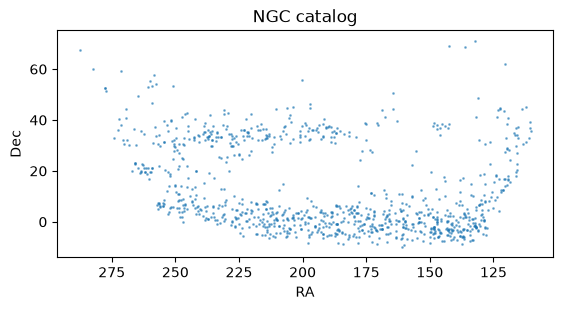

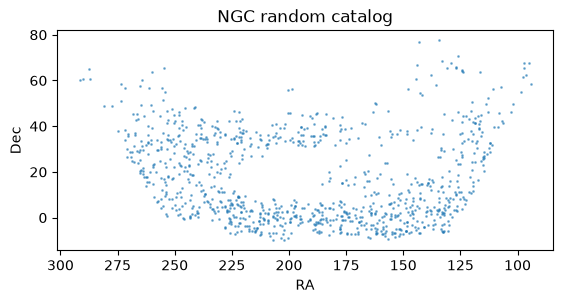

In [4]:
fig, ax = plt.subplots()
ax.scatter(data['RA'], data['DEC'], s=1, alpha=0.5)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA')
ax.set_ylabel('Dec')
ax.set_title('NGC catalog')
plt.show()

fig, ax = plt.subplots()
ax.scatter(rand['RA'], rand['DEC'], s=1, alpha=0.5)
ax.axis('scaled')
ax.xaxis.set_inverted(True)
ax.set_xlabel('RA')
ax.set_ylabel('Dec')
ax.set_title('NGC random catalog')
plt.show()

## choose bins

In [5]:
r_max = (QUERY_RADIUS_ARCMIN * u.arcmin).to(u.rad).value \
        * Planck18.comoving_transverse_distance(Z_MAX).to(u.Mpc).value
r_bins = np.linspace(0, r_max, 32)

# narrow rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every galaxy's redshifted H-alpha window
QUERY_WL_MIN = WL_REST_MIN * (1 + Z_MIN)
QUERY_WL_MAX = WL_REST_MAX * (1 + Z_MAX)

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1

## query & stack

In [6]:
def query_ranges_sql(ra, dec, radius_deg, level=13):
    ipix_L = hp.query_disc(
        2**level, hp.ang2vec(ra, dec, lonlat=True),
        np.radians(radius_deg), nest=True, inclusive=True,
    )
    ranges = indices_to_hphigh_ranges(ipix_L, level)

    return '(' + '\nOR '.join(
        f'(p.hphigh BETWEEN {lo} AND {hi})'
        for (lo, hi) in ranges
    ) + ')'

def pixels_table_sql(ra, dec, radius_deg):
    part_nums = find_partitions_disc(ra, dec, radius_deg)
    paths_sql = ','.join([
        f"'/mnt/sdceph/users/spherex/talltable/pixels/part={p}/compacted.parquet'"
        for p in part_nums
    ])
    if len(part_nums) > 1:
        paths_sql = f'[{paths_sql}]'
    return f"read_parquet({paths_sql})"

def query_gaia(ra, dec, radius_deg, mag_limit=20.0):
    coord = SkyCoord(ra=ra, dec=dec, frame="icrs", unit="deg")
 
    table = Irsa.query_region(
        coord,
        catalog="gaia_dr3_source",
        spatial="Cone",
        radius=radius_deg * u.deg,
        columns="source_id,ra,dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag",
    )

    # hard cut on G magnitude
    table = table[table["phot_g_mean_mag"] < mag_limit]
    return table

def spherex_mask_radius(m, band):
    a, b, c, d, e = {
        1: (1549.4, -0.568, 21.7, -0.114, -1.17),
        2: (2687.3, -0.700, 452.1, -0.003, -430.3),
        3: (1129.4, -0.496, 396.4, -0.0002, -392.3),
        4: (2277.9, -0.575, 1102.5, -0.0003, -1095.0),
        5: (1072.98, -0.44, 11491.65, 5e-5, -11499.76),
        6: (1291.4, -0.522, 1579.8, -0.0002, -1571.3),
    }[band]

    return a * np.exp(b * m) + c * np.exp(d * m) + e

def crude_mask_radius(m):
    return 8.0 + 4e3 * 10 ** (-0.25 * m)

def query_gaia_retry(ra, dec, radius_deg, max_retries=5):
    for attempt in range(max_retries):
        try:
            return query_gaia(ra, dec, radius_deg)
        except DALServiceError as e:
            if attempt == max_retries - 1:
                raise
            wait = 2 ** attempt + np.random.uniform(0, 1)
            time.sleep(wait)

_local = threading.local()

def get_con():
    if not hasattr(_local, "con"):
        _local.con = duckdb.connect()
    return _local.con

def process_row(row):
    ra, dec, z = row['RA'], row['DEC'], row['Z']

    gaia_sources = query_gaia_retry(ra, dec, (QUERY_RADIUS_ARCMIN + 0.5) / 60)
    mask_ranges_sql = '\nAND '.join([
        'NOT ' + query_ranges_sql(
            src['ra'], src['dec'],
            crude_mask_radius(src['phot_g_mean_mag']) / 3600,
            level=15,
        ) for src in gaia_sources
    ])
    if mask_ranges_sql == "":
        mask_ranges_sql = "1"

    query = f"""
WITH waves AS (
    SELECT * FROM read_parquet('/mnt/sdceph/users/spherex/talltable/waves.parquet')
    WHERE wavelength BETWEEN {QUERY_WL_MIN} AND {QUERY_WL_MAX}
)
SELECT p.imageid, p.flux, p.zodi, p.variance, p.hphigh, p.waveid
     , w.wavelength, w.bandwidth
FROM {pixels_table_sql(ra, dec, QUERY_RADIUS_ARCMIN / 60)} p
JOIN waves w ON p.waveid = w.waveid
WHERE {query_ranges_sql(ra, dec, QUERY_RADIUS_ARCMIN / 60)}
AND ({mask_ranges_sql})
AND (p.flags & ~(1 << 21) = 0)
"""
    _table = get_con().sql(query).to_arrow_table()

    gal_coord = SkyCoord(ra=ra, dec=dec, unit='deg')
    pra, pdec = hp.pix2ang(2**22, _table.column("hphigh").to_numpy(), nest=True, lonlat=True)
    pixel_coords = SkyCoord(ra=pra, dec=pdec, unit='deg')

    dist = gal_coord.separation(pixel_coords).to(u.rad).value \
           * Planck18.comoving_transverse_distance(z)
    r_rest = dist.to(u.Mpc).value

    wavelen_obs   = _table.column("wavelength").to_numpy()
    freq_obs      = (const.c / (wavelen_obs * u.micrometer)).to(u.Hz).value
    intensity_obs = freq_obs * (_table.column("flux").to_numpy() - _table.column("zodi").to_numpy())

    wl_rest = wavelen_obs / (1 + z)
    I_rest  = (1 + z)**4 * intensity_obs

    i_r  = np.digitize(r_rest,  r_bins)  - 1
    i_wl = np.digitize(wl_rest, wl_bins) - 1
    valid = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)

    return i_r[valid], i_wl[valid], I_rest[valid]

In [ ]:
sum_I_D  = np.zeros((n_r, n_wl))
sum_I2_D = np.zeros((n_r, n_wl))
count_D  = np.zeros((n_r, n_wl), dtype=np.int64)

with ThreadPoolExecutor(max_workers=8) as ex:
    futures = [ex.submit(process_row, row) for row in data]
    try:
        for fut in tqdm(as_completed(futures), total=len(data)):
            i_r_v, i_wl_v, I_v = fut.result()
            np.add.at(sum_I_D,  (i_r_v, i_wl_v), I_v)
            np.add.at(sum_I2_D, (i_r_v, i_wl_v), I_v ** 2)
            np.add.at(count_D,  (i_r_v, i_wl_v), 1)
    except Exception:
        for f in futures:
            f.cancel()
        ex.shutdown(wait=False, cancel_futures=True)
        raise

  0%|          | 0/1000 [00:00<?, ?it/s]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (58 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [ ]:
sum_I_R  = np.zeros((n_r, n_wl))
sum_I2_R = np.zeros((n_r, n_wl))
count_R  = np.zeros((n_r, n_wl), dtype=np.int64)

with ThreadPoolExecutor(max_workers=8) as ex:
    futures = [ex.submit(process_row, row) for row in rand]
    for fut in tqdm(as_completed(futures), total=len(rand)):
        i_r_v, i_wl_v, I_v = fut.result()
        np.add.at(sum_I_R,  (i_r_v, i_wl_v), I_v)
        np.add.at(sum_I2_R, (i_r_v, i_wl_v), I_v ** 2)
        np.add.at(count_R,  (i_r_v, i_wl_v), 1)

In [ ]:
J = np.where(count_R > 0, (sum_I_D - sum_I_R) / count_R, np.nan)

r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

In [ ]:
cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(r_c.min(), r_c.max())

fig, ax = plt.subplots()
for i in range(n_r):
    ax.errorbar(wl_c * 1e3, J[i], marker='o', color=cmap(norm(r_c[i])))
ax.set_xlabel('wavelength [nm]')
ax.set_ylabel(r'$J$')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$r$ [cMpc]')
plt.show()


cmap = plt.get_cmap('inferno')
norm = mpl.colors.Normalize(wl_c.min()* 1e3, wl_c.max()* 1e3)

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.errorbar(r_c, J[:, j], marker='o', color=cmap(norm(wl_c[j] * 1e3)))
ax.set_xlabel('$r$ [cMpc]')
ax.set_ylabel(r'$J$')
# ax.set_yscale('log')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$\lambda_{\rm rf}$ [nm]')
plt.show()

h_alpha_index = np.argmin(np.abs(wl_c - WL_REST_HALPHA))
print(h_alpha_index)

fig, ax = plt.subplots()
ax.plot(r_c, J[:, h_alpha_index], marker='o')
ax.set_xlabel('$r$ [cMpc]')
ax.set_ylabel(r'$J$')
ax.set_title(r'$\lambda_{\rm rf} = 656 \ {\rm nm}$')
plt.show()

In [ ]:
cmap = plt.get_cmap('rainbow')
norm = mpl.colors.Normalize(wl_bins.min(), wl_bins.max())

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.plot(r_c, count_D[:, j], color=cmap(norm(wl_c[j])), marker='o', label=f'{wl_c[j]:.2f} um')
ax.set_xlabel('r_comoving [Mpc]')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label='Wavelength [µm]')
ax.set_yscale('log')
ax.set_ylabel("Measurement count")
plt.show()

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.plot(r_c, count_R[:, j], color=cmap(norm(wl_c[j])), marker='o', label=f'{wl_c[j]:.2f} um')
ax.set_xlabel('r_comoving [Mpc]')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label='Wavelength [µm]')
ax.set_yscale('log')
ax.set_ylabel("Measurement count")
plt.show()

In [ ]:
avg_D = np.where(count_D > 0, sum_I_D / count_D, np.nan)
avg_R = np.where(count_R > 0, sum_I_R / count_R, np.nan)
avg_diff = avg_D - avg_R

cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(r_c.min(), r_c.max())

fig, ax = plt.subplots()
for i in range(n_r):
    ax.errorbar(wl_c * 1e3, avg_diff[i], marker='o', color=cmap(norm(r_c[i])))
ax.set_xlabel('wavelength [nm]')
ax.set_ylabel(r'Avg diff')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$r$ [cMpc]')
plt.show()


cmap = plt.get_cmap('inferno')
norm = mpl.colors.Normalize(wl_c.min()* 1e3, wl_c.max()* 1e3)

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.errorbar(r_c, avg_diff[:, j], marker='o', color=cmap(norm(wl_c[j] * 1e3)))
ax.set_xlabel('$r$ [cMpc]')
ax.set_ylabel(r'Avg diff')
# ax.set_yscale('log')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$\lambda_{\rm rf}$ [nm]')
plt.show()

fig, ax = plt.subplots()
ax.plot(r_c, avg_diff[:, h_alpha_index], marker='o')
ax.set_xlabel('$r$ [cMpc]')
ax.set_ylabel(r'Avg diff')
ax.set_title(r'$\lambda_{\rm rf} = 656 \ {\rm nm}$')
plt.show()